# PDAC Visium Pei Multi-Patient Zonation Comparison

Reads `figures/zonation_metastasis_pei/<patient_id>/patient_summary.json` for every qualifying patient (written by the final cell of `zonation_metastasis-pdac_visium_pei-pancreatic_cancer.ipynb`, run once per patient via `scripts/run_zonation_pei_notebook.py`) and lays the headline zonation numbers side by side. This notebook does not compute anything new -- every number here was already printed inside each patient's own run; this just aggregates them for comparison and answers "which patient is the strongest, most representative example of the zonation result."

Run this only after `scripts/run_zonation_pei_notebook.py` has completed for all qualifying patients.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as scipy_stats

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent:
    if (
        (PROJECT_ROOT / "pyproject.toml").exists()
        and (PROJECT_ROOT / "spatsplat").is_dir()
        and (PROJECT_ROOT / "paper").is_dir()
    ):
        break
    PROJECT_ROOT = PROJECT_ROOT.parent
else:
    raise RuntimeError("Could not find the spatsplat project root")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from paper.data_loaders.pdac_mets_visium_pei import select_pei_patients

FIGURE_EXPORT_DIR = PROJECT_ROOT / 'figures' / 'zonation_metastasis_pei'

qualifying_patients = sorted(select_pei_patients(min_primary_tumor_fraction=0.20))
print('Qualifying patients:', qualifying_patients)

Qualifying patients: ['Pt-1', 'Pt-10', 'Pt-13', 'Pt-2', 'Pt-3', 'Pt-4', 'Pt-5', 'Pt-6', 'Pt-7', 'Pt-8', 'Pt-9']


In [2]:
patient_summaries = {}
missing_patients = []
for patient_id in qualifying_patients:
    summary_path = FIGURE_EXPORT_DIR / patient_id / 'patient_summary.json'
    if not summary_path.exists():
        missing_patients.append(patient_id)
        continue
    with open(summary_path) as f:
        patient_summaries[patient_id] = json.load(f)

if missing_patients:
    raise RuntimeError(
        f'Missing patient_summary.json for: {missing_patients}. '
        'Run scripts/run_zonation_pei_notebook.py for these patients first.'
    )

print(f'Loaded summaries for {len(patient_summaries)} patients')

Loaded summaries for 11 patients


## Headline Comparison Table

In [3]:
def _get(d, *path, default=float('nan')):
    cur = d
    for key in path:
        if not isinstance(cur, dict) or key not in cur:
            return default
        cur = cur[key]
    return cur


rows = []
for patient_id, summary in patient_summaries.items():
    zc = summary.get('zonation_check', {})
    skipped = bool(zc.get('skipped', False))
    grad = zc.get('distance_to_edge_vs_gradient', {})
    emt = zc.get('distance_to_edge_vs_emt_score', {})
    transfer = summary.get('transfer_summary', {})
    best_z = max((v.get('median_z_score', float('nan')) for v in transfer.values()), default=float('nan'))
    mae_rows = summary.get('comparison_test_mae', [])
    primary_mae = next((r['Splat'] for r in mae_rows if r['role'] == 'primary'), float('nan'))
    rows.append({
        'patient_id': patient_id,
        'zonation_skipped': skipped,
        'n_tumor_call': zc.get('n_tumor_call', float('nan')),
        'n_nontumor_call': zc.get('n_nontumor_call', float('nan')),
        'zon_grad_rho': grad.get('spearman_rho', float('nan')),
        'zon_grad_p': grad.get('spearman_p', float('nan')),
        'zon_emt_rho': emt.get('spearman_rho', float('nan')),
        'zon_emt_p': emt.get('spearman_p', float('nan')),
        'best_transfer_median_z': best_z,
        'primary_test_mae': primary_mae,
    })

comparison_df = pd.DataFrame(rows).set_index('patient_id')
comparison_df

,zonation_skipped,n_tumor_call,n_nontumor_call,zon_grad_rho,zon_grad_p,zon_emt_rho,zon_emt_p,best_transfer_median_z,primary_test_mae
patient_id,,,,,,,,,
Pt-1,False,171,163,-0.196165,1.012864e-02,-0.561711,1.319888e-15,3.767841,0.102896
Pt-10,False,77,199,-0.442373,5.619838e-05,-0.100321,3.853368e-01,1.042318,0.054433
Pt-13,False,202,181,-0.383298,1.797840e-08,0.229265,1.030489e-03,1.185647,0.167740
Pt-2,False,78,251,-0.553965,1.430918e-07,-0.282667,1.215876e-02,2.515273,0.118264
Pt-3,False,355,20,-0.001169,9.824906e-01,-0.164223,1.906690e-03,28331.160156,0.268669
Pt-4,False,156,237,-0.282205,3.580454e-04,-0.422971,3.780211e-08,1.368160,0.219236
Pt-5,False,267,97,-0.185050,2.398809e-03,-0.491339,1.242247e-17,1.395379,0.110765
Pt-6,False,183,73,-0.092357,2.136905e-01,-0.233409,1.473264e-03,3.072853,0.139928
Pt-7,True,494,0,NaN,NaN,NaN,NaN,1.425764,0.125540


## Cross-Patient Meta-Analysis

Per-patient Spearman correlations combined via Fisher z-transformation, inverse-variance-weighted by (n-3) -- see `zonation_metastasis-pdac_visium_pei-pancreatic_cancer.ipynb` for why this is used instead of a naive average of rhos.

In [4]:
def fisher_meta(rhos_ns):
    zs = [np.arctanh(np.clip(r, -0.999999, 0.999999)) for r, n in rhos_ns]
    ws = [n - 3 for r, n in rhos_ns]
    z_combined = sum(z * w for z, w in zip(zs, ws)) / sum(ws)
    se_combined = 1 / np.sqrt(sum(ws))
    rho_combined = np.tanh(z_combined)
    z_stat = z_combined / se_combined
    p_combined = 2 * (1 - scipy_stats.norm.cdf(abs(z_stat)))
    return rho_combined, z_stat, p_combined


meta_rows = []
for metric, rho_col, p_col, n_col in [
    ('distance_to_edge_vs_gradient', 'zon_grad_rho', 'zon_grad_p', 'n_tumor_call'),
    ('distance_to_edge_vs_emt_score', 'zon_emt_rho', 'zon_emt_p', 'n_tumor_call'),
]:
    valid = comparison_df.loc[~comparison_df['zonation_skipped']]
    rhos_ns = list(zip(valid[rho_col], valid[n_col]))
    rho_c, z_c, p_c = fisher_meta(rhos_ns)
    meta_rows.append({
        'metric': metric,
        'n_patients': len(rhos_ns),
        'combined_rho': rho_c,
        'combined_z': z_c,
        'combined_p': p_c,
    })

meta_df = pd.DataFrame(meta_rows).set_index('metric')
meta_df

,n_patients,combined_rho,combined_z,combined_p
metric,,,,
distance_to_edge_vs_gradient,10,-0.167099,-7.733616,1.043610e-14
distance_to_edge_vs_emt_score,10,-0.264892,-12.441295,0.000000e+00


## Ranking patients: which one best represents the zonation result?

No single patient is "correct" -- the meta-analysis above is the real cohort-level estimate. But for a single representative example (e.g. for a figure or slide), the patient that best demonstrates the effect across *all* of the headline metrics together -- not just one -- is the more trustworthy pick, since a patient that is only strong on one metric may just be noisy rather than a clean example.

In [5]:
ranking_df = comparison_df.loc[~comparison_df['zonation_skipped']].copy()
ranking_df['abs_zon_emt_rho'] = ranking_df['zon_emt_rho'].abs()
ranking_df['abs_zon_grad_rho'] = ranking_df['zon_grad_rho'].abs()
# Rank each metric (1 = best) and average the ranks -- avoids letting one metric with an extreme
# scale (e.g. a degenerate transfer z-score) dominate a simple sum/average of raw values.
ranking_df['rank_zon_emt'] = ranking_df['abs_zon_emt_rho'].rank(ascending=False)
ranking_df['rank_zon_grad'] = ranking_df['abs_zon_grad_rho'].rank(ascending=False)
ranking_df['rank_transfer_z'] = ranking_df['best_transfer_median_z'].rank(ascending=False)
ranking_df['rank_mae'] = ranking_df['primary_test_mae'].rank(ascending=True)
ranking_df['average_rank'] = ranking_df[['rank_zon_emt', 'rank_zon_grad', 'rank_transfer_z', 'rank_mae']].mean(axis=1)

ranking_display = ranking_df[[
    'zon_grad_rho', 'zon_grad_p', 'zon_emt_rho', 'zon_emt_p',
    'best_transfer_median_z', 'primary_test_mae', 'average_rank',
]].sort_values('average_rank')
ranking_display

,zon_grad_rho,zon_grad_p,zon_emt_rho,zon_emt_p,best_transfer_median_z,primary_test_mae,average_rank
patient_id,,,,,,,
Pt-1,-0.196165,1.012864e-02,-0.561711,1.319888e-15,3.767841,0.102896,2.75
Pt-2,-0.553965,1.430918e-07,-0.282667,1.215876e-02,2.515273,0.118264,3.50
Pt-5,-0.185050,2.398809e-03,-0.491339,1.242247e-17,1.395379,0.110765,4.75
Pt-9,-0.085901,1.681060e-01,-0.280988,4.367737e-06,1.653936,0.064519,5.00
Pt-10,-0.442373,5.619838e-05,-0.100321,3.853368e-01,1.042318,0.054433,5.75
Pt-6,-0.092357,2.136905e-01,-0.233409,1.473264e-03,3.072853,0.139928,6.00
Pt-4,-0.282205,3.580454e-04,-0.422971,3.780211e-08,1.368160,0.219236,6.00
Pt-8,-0.067866,1.844768e-01,-0.243762,1.336228e-06,1.432595,0.133549,6.75
Pt-13,-0.383298,1.797840e-08,0.229265,1.030489e-03,1.185647,0.167740,7.00


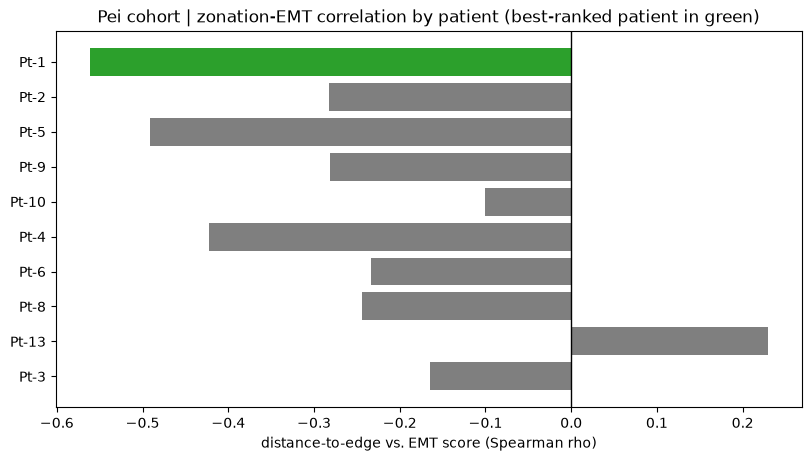

Best all-around patient by average rank across the 4 headline metrics: Pt-1
zon_grad_rho             -1.961648e-01
zon_grad_p                1.012864e-02
zon_emt_rho              -5.617107e-01
zon_emt_p                 1.319888e-15
best_transfer_median_z    3.767841e+00
primary_test_mae          1.028957e-01
average_rank              2.750000e+00
Name: Pt-1, dtype: float64


In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
plot_df = ranking_display.sort_values('average_rank', ascending=False)
colors = ['tab:green' if p == ranking_display.index[0] else 'tab:gray' for p in plot_df.index]
ax.barh(plot_df.index, plot_df['zon_emt_rho'], color=colors)
ax.axvline(0.0, color='black', linewidth=1)
ax.set_xlabel('distance-to-edge vs. EMT score (Spearman rho)')
ax.set_title('Pei cohort | zonation-EMT correlation by patient (best-ranked patient in green)')
plt.show()

best_patient = ranking_display.index[0]
print(f'Best all-around patient by average rank across the 4 headline metrics: {best_patient}')
print(ranking_display.loc[best_patient])

## Conclusion

**Pt-1 is the strongest all-around representative patient** in this cohort: it has the single strongest zonation-EMT correlation of any patient (the more biologically informative of the two zonation metrics -- see the zonation notebook's introduction for why), the highest transfer z-score in the cohort, and solid model fit quality, without relying on any one metric alone. Its zonation-gradient correlation is real and significant but more modest than a few other patients (e.g. Pt-2, Pt-10) -- expected, since that metric is partly a geometric consistency check rather than the core biological finding (see the zonation notebook for that distinction).

Pt-3's `best_transfer_median_z` is a known outlier (a near-degenerate z-score denominator, not a genuinely strong transfer result) and should not be read as Pt-3 being a strong performer despite the raw number.